# Bài 00: Khởi động — Làm chủ Môi trường và Bức tranh Toàn cảnh Xử lý Ảnh & AI

## 1. Mục tiêu học tập (Learning Objectives)
Sau khi hoàn thành bài học này, bạn sẽ:
- Kiểm tra được phiên bản `Python`, các thư viện cốt lõi (`NumPy`, `OpenCV`, `Pillow`, `scikit-learn`, `PyTorch`, `torchvision`) và thiết bị tính toán (`CPU` / `GPU CUDA`).
- Hiểu cơ chế xác định thư mục gốc dự án (`project_root`) bằng đường dẫn tương đối để code chạy ổn định trên mọi máy tính.
- Hiểu ý nghĩa của cờ cấu hình `QUICK_RUN` (chế độ kiểm tra nhanh pipeline so với chế độ huấn luyện đầy đủ).
- Phân biệt rõ 4 khái niệm nền tảng: **Image Processing (Xử lý ảnh)**, **Computer Vision (Thị giác máy tính)**, **Machine Learning (Học máy)** và **Deep Learning (Học sâu)**.
- Phân biệt phương pháp xử lý ảnh bằng **thuật toán cố định (Rule-based)** với **mô hình học từ dữ liệu (Data-driven model)**.

## 2. Kiến thức cần có (Prerequisites)
- Biết thao tác mở file trong JupyterLab hoặc VS Code.
- Không yêu cầu kiến thức toán cao cấp hay học sâu trước đó.

## 3. Thời gian học dự kiến (Estimated Time)
- Khoảng **45 – 60 phút** (chỉ là ước tính tham khảo; hãy ưu tiên hiểu sâu thay vì chạy nhanh).

## 4. Bài toán thực tế đơn giản (Practical Problem)
Giả sử bạn cần xây dựng chương trình kiểm tra xem một bức ảnh chụp sản phẩm trên băng chuyền là **sáng rõ hay bị tối**, và nhận diện hình dạng vật thể (`circle`, `square`, `triangle`, `cross`).
- Với yêu cầu "kiểm tra ảnh sáng hay tối": Một công thức tính trung bình độ sáng cố định là đủ.
- Với yêu cầu "phân loại hình dạng khi vật thể bị xoay, đổi màu, nhiễu nền": Luật cố định rất dễ vỡ, cần mô hình học từ dữ liệu.

## 5. Giải thích trực quan & Phân biệt Khái niệm
```
┌─────────────────────────────────────────────────────────────────────────┐
│ Artificial Intelligence (AI - Trí tuệ nhân tạo)                         │
│   ┌─────────────────────────────────────────────────────────────────┐   │
│   │ Machine Learning (ML - Học máy: Học quy luật từ dữ liệu mẫu)    │   │
│   │   ┌─────────────────────────────────────────────────────────┐   │   │
│   │   │ Deep Learning (DL - Học sâu: Mạng nơ-ron nhiều tầng     │   │   │
│   │   │ tự động học cả đặc trưng lẫn bộ phân loại: CNN, ViT...) │   │   │
│   │   └─────────────────────────────────────────────────────────┘   │   │
│   └─────────────────────────────────────────────────────────────────┘   │
└─────────────────────────────────────────────────────────────────────────┘
```
- **Image Processing (Xử lý ảnh)**: Đầu vào là **Ảnh** → Đầu ra thường là **Ảnh đã biến đổi** (làm nét, khử nhiễu, cân bằng sáng, tách biên).
- **Computer Vision (Thị giác máy tính)**: Đầu vào là **Ảnh/Video** → Đầu ra là **Thông tin hiểu biết / Quyết định** (nhãn lớp, tọa độ khung vật thể, văn bản đọc được).

## 6. Thuật ngữ mới & Giải thích Keyword
| Thuật ngữ tiếng Anh | Nghĩa tiếng Việt | Nhóm | Vai trò & Giải thích chi tiết |
|---|---|---|---|
| `project_root` | Thư mục gốc dự án | Triển khai | Đường dẫn gốc `image_ai_learning/` giúp nạp dữ liệu và lưu kết quả bằng đường dẫn tương đối (`relative path`), tránh lỗi đường dẫn cứng (`hardcoded absolute path`). |
| `seed` | Hạt giống ngẫu nhiên | Huấn luyện | Số nguyên dương (ví dụ `42`) cố định chuỗi số giả ngẫu nhiên trong `random`, `numpy`, `torch` để kết quả có tính tái lập (`reproducibility`). |
| `device` | Thiết bị tính toán | Triển khai | Đối tượng `torch.device('cpu')` hoặc `torch.device('cuda')` chỉ định nơi lưu trữ Tensor và thực hiện phép nhân ma trận. |
| `QUICK_RUN` | Chế độ chạy kiểm tra nhanh | Huấn luyện | Biến `bool` (`True`/`False`). Khi `True`, giảm số mẫu và số `epochs` để kiểm tra luồng code trong vài giây trên CPU. **Lưu ý**: Không dùng điểm số của `QUICK_RUN` để kết luận chất lượng tối đa của mô hình. |

## 7. Công thức cần thiết & Ví dụ số nhỏ
Khi đánh giá độ sáng trung bình $\mu$ của một bức ảnh thang xám (Grayscale) có chiều cao $H$ và chiều rộng $W$:
$$\mu = \frac{1}{H \times W} \sum_{y=0}^{H-1} \sum_{x=0}^{W-1} I(y, x)$$
- Ký hiệu:
  - $I(y, x) \in \{0, 1, \dots, 255\}$: Cường độ sáng tại hàng $y$, cột $x$ (`0` là đen tuyệt đối, `255` là trắng tuyệt đối).
  - $H, W$: Chiều cao (`height`) và chiều rộng (`width`) tính theo số điểm ảnh (`pixels`).
- **Ví dụ số nhỏ**: Với ảnh `2x2` có ma trận điểm ảnh $\begin{bmatrix} 10 & 20 \\ 30 & 200 \end{bmatrix}$, độ sáng trung bình là:
  $$\mu = \frac{10 + 20 + 30 + 200}{2 \times 2} = \frac{260}{4} = 65.0$$


In [1]:
# Cell 1: Thiết lập đường dẫn tương đối tới thư mục gốc dự án và kiểm tra môi trường
import sys
import platform
from pathlib import Path

# Tự động tìm thư mục gốc image_ai_learning dù chạy từ bất kỳ đâu
current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import cv2
import PIL
import sklearn
import torch
import torchvision

from src.utils import find_project_root, set_seed, get_device
from src.synthetic_data import generate_synthetic_shapes_dataset

QUICK_RUN = True
SEED = 42
set_seed(SEED)
device = get_device()

print(f"Project Root (tương đối): {find_project_root().name}")
print(f"Python version          : {platform.python_version()}")
print(f"NumPy version           : {np.__version__}")
print(f"OpenCV version          : {cv2.__version__}")
print(f"scikit-learn version    : {sklearn.__version__}")
print(f"PyTorch version         : {torch.__version__}")
print(f"Torchvision version     : {torchvision.__version__}")
print(f"Active Device           : {device} (CUDA available: {torch.cuda.is_available()})")
print(f"QUICK_RUN mode          : {QUICK_RUN}")


Project Root (tương đối): image_ai_learning
Python version          : 3.12.10
NumPy version           : 2.5.2
OpenCV version          : 5.0.0
scikit-learn version    : 1.9.1
PyTorch version         : 2.14.1+cpu
Torchvision version     : 0.29.1+cpu
Active Device           : cpu (CUDA available: False)
QUICK_RUN mode          : True


Images shape: (16, 32, 32, 3), dtype: uint8, min=0, max=255
Labels shape: (16,), dtype: int64, classes: ['circle', 'square', 'triangle', 'cross']


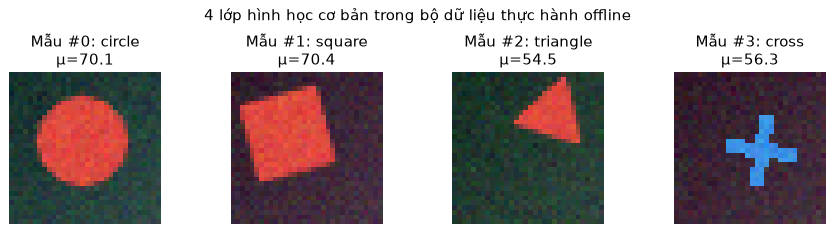

In [2]:
# Cell 2: Tạo tập dữ liệu ảnh tổng hợp đầu tiên và hiển thị 4 lớp hình học
dataset_demo = generate_synthetic_shapes_dataset(
    num_samples=16 if QUICK_RUN else 64,
    image_size=32,
    seed=SEED,
    noise_std=8.0,
)
images = dataset_demo["images"]
labels = dataset_demo["labels"]
class_names = dataset_demo["class_names"]

print(f"Images shape: {images.shape}, dtype: {images.dtype}, min={images.min()}, max={images.max()}")
print(f"Labels shape: {labels.shape}, dtype: {labels.dtype}, classes: {class_names}")

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
for i in range(4):
    axes[i].imshow(images[i])
    axes[i].set_title(f"Mẫu #{i}: {class_names[labels[i]]}\nμ={images[i].mean():.1f}")
    axes[i].axis("off")
plt.suptitle("4 lớp hình học cơ bản trong bộ dữ liệu thực hành offline", fontsize=12)
plt.tight_layout()
plt.show()


In [3]:
# Cell 3: Minh họa sự khác biệt giữa Luật cố định (Rule-based) và Học từ dữ liệu (Data-driven)
# Giả sử ta thử phân loại 4 hình trên chỉ bằng 1 ngưỡng "độ sáng trung bình" cố định:
mean_intensities = images.mean(axis=(1, 2, 3))
for cls_idx, cls_name in enumerate(class_names):
    cls_means = mean_intensities[labels == cls_idx]
    print(f"Lớp {cls_name:8s} -> Độ sáng trung bình: {cls_means.mean():.2f} ± {cls_means.std():.2f}")

# Nhận xét: Các lớp chồng lấp độ sáng rất mạnh, nên luật ngưỡng độ sáng cố định không thể tách 4 hình dạng!


Lớp circle   -> Độ sáng trung bình: 73.88 ± 7.39
Lớp square   -> Độ sáng trung bình: 77.29 ± 9.71
Lớp triangle -> Độ sáng trung bình: 63.67 ± 5.83
Lớp cross    -> Độ sáng trung bình: 59.38 ± 4.07


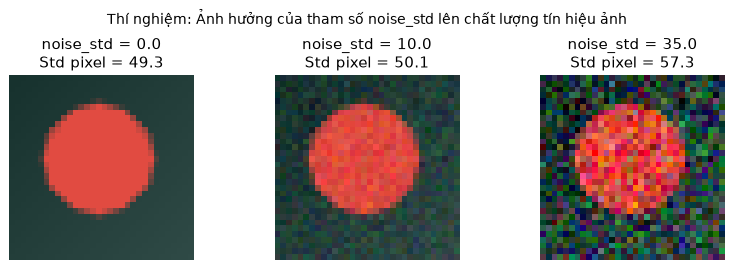

In [4]:
# Cell 4: Thí nghiệm thay đổi một yếu tố (Single-Factor Experiment)
# Thay đổi mức độ nhiễu cảm biến (noise_std) từ 0.0 -> 10.0 -> 35.0 và quan sát tác động lên ảnh
noise_levels = [0.0, 10.0, 35.0]
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for idx, n_std in enumerate(noise_levels):
    ds_temp = generate_synthetic_shapes_dataset(num_samples=4, image_size=32, seed=SEED, noise_std=n_std)
    img_sample = ds_temp["images"][0]
    axes[idx].imshow(img_sample)
    axes[idx].set_title(f"noise_std = {n_std}\nStd pixel = {img_sample.std():.1f}")
    axes[idx].axis("off")
plt.suptitle("Thí nghiệm: Ảnh hưởng của tham số noise_std lên chất lượng tín hiệu ảnh", fontsize=11)
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- Ở **Cell 2**, mảng `images` có `shape = (16, 32, 32, 3)` nghĩa là gồm `16` bức ảnh, mỗi ảnh cao `32` pixel, rộng `32` pixel và có `3` kênh màu (`R, G, B`), kiểu dữ liệu `uint8` (`0..255`).
- Ở **Cell 3**, độ sáng trung bình giữa 4 lớp (`circle`, `square`, `triangle`, `cross`) xấp xỉ nhau với độ lệch chuẩn chồng lấn mạnh. Điều này giải thích vì sao các bài toán nhận dạng hình ảnh cần trích xuất đặc trưng hình học hoặc học sâu thay vì dùng một ngưỡng cường độ sáng cố định.
- Ở **Cell 4**, khi tăng `noise_std` lên `35.0`, biên của hình tròn bị lẫn vào nhiễu nền, báo hiệu các thuật toán đạo hàm bậc nhất nhạy nhiễu sẽ cần bước làm mượt trước khi tách biên.

## 13. Lỗi thường gặp và cách sửa (Common Pitfalls)
1. **Chọn sai Jupyter Kernel**: Nếu gặp `ModuleNotFoundError: No module named 'torch'`, hãy nhìn góc trên bên phải cửa sổ notebook và chọn kernel `.venv (Python 3.12)`.
2. **Dùng đường dẫn tuyệt đối của máy cá nhân**: Không viết `C:/Users/TenBan/...` trong code. Hãy luôn dùng `project_root / "data" / ...` như ở Cell 1.
3. **Quên cố định `seed`**: Khi so sánh hai thuật toán mà không gọi `set_seed(42)`, sự khác biệt kết quả có thể đến từ may rủi lúc khởi tạo ngẫu nhiên chứ không phải do thuật toán tốt hơn.

## 14. Bài tập tự làm (Exercises)
- **Mức Cơ bản**: Tạo bộ dữ liệu gồm `8` ảnh với kích thước `image_size = 48` và in ra `shape`, `dtype`, giá trị nhỏ nhất (`min`), lớn nhất (`max`) của mảng ảnh.
- **Mức Trung cấp**: Viết hàm `check_brightness_status(img, low_thresh=40.0, high_thresh=200.0)` trả về `"too_dark"`, `"normal"`, hoặc `"too_bright"` dựa trên độ sáng trung bình của ảnh.
- **Mức Nâng cao**: Thử nghiệm thay đổi `seed` qua 5 giá trị `[1, 2, 3, 4, 5]`, tính độ sáng trung bình của toàn bộ tập `16` ảnh ở mỗi `seed` để kiểm chứng mức độ ổn định thống kê.

## 15. Gợi ý và Lời giải (Hints & Complete Solutions)
- *Gợi ý*: Dùng `.mean()` trên mảng NumPy và cấu trúc rẽ nhánh `if / elif / else`. Cell bên dưới cung cấp lời giải chạy được hoàn chỉnh.


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho 3 bài tập tự làm
# 1. Bài tập Cơ bản
ds_ex1 = generate_synthetic_shapes_dataset(num_samples=8, image_size=48, seed=42)
imgs_ex1 = ds_ex1["images"]
print("[Cơ bản] Shape:", imgs_ex1.shape, "| Dtype:", imgs_ex1.dtype, "| Min/Max:", imgs_ex1.min(), imgs_ex1.max())

# 2. Bài tập Trung cấp
def check_brightness_status(img: np.ndarray, low_thresh: float = 40.0, high_thresh: float = 200.0) -> str:
    mean_val = float(img.mean())
    if mean_val < low_thresh:
        return "too_dark"
    if mean_val > high_thresh:
        return "too_bright"
    return "normal"

print("[Trung cấp] Trạng thái ảnh #0:", check_brightness_status(imgs_ex1[0]))

# 3. Bài tập Nâng cao
seed_means = []
for s in [1, 2, 3, 4, 5]:
    ds_s = generate_synthetic_shapes_dataset(num_samples=16, image_size=32, seed=s)
    seed_means.append(float(ds_s["images"].mean()))
print("[Nâng cao] Độ sáng trung bình qua 5 seeds:", [round(v, 2) for v in seed_means])


[Cơ bản] Shape: (8, 48, 48, 3) | Dtype: uint8 | Min/Max: 0 255
[Trung cấp] Trạng thái ảnh #0: normal
[Nâng cao] Độ sáng trung bình qua 5 seeds: [67.28, 65.94, 66.91, 64.31, 64.82]


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã xác nhận import thành công `numpy`, `cv2`, `sklearn`, `torch`, `torchvision`.
- [x] Đã hiểu ý nghĩa của `project_root`, `seed`, `device`, `QUICK_RUN`.
- [x] Sẵn sàng chuyển sang **Bài 01: `01_python_numpy_for_images.ipynb`** để nắm vững cấu trúc mảng đa chiều cho xử lý ảnh.

## 17. Nguồn tham khảo (References)
- Tài liệu chính thức PyTorch: https://pytorch.org/docs/stable/index.html
- Tài liệu chính thức NumPy: https://numpy.org/doc/stable/
- Szeliski, R. (2022), *Computer Vision: Algorithms and Applications* (2nd ed.), Springer.
